<a href="https://colab.research.google.com/github/oloyededavid/Coastal-Hydrogeology-Modeling/blob/main/code/Lekki_Hydro_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install earthengine-api rasterio scikit-image geopandas -q

import time
import json
from pathlib import Path
from google.colab import drive
import ee
import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.ndimage import gaussian_filter, laplace
from skimage.graph import route_through_array
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

drive.mount('/content/drive')

DRIVE_FOLDER = "Lekki_Hydro_Study"
DATA_DIR = Path(f"/content/drive/MyDrive/{DRIVE_FOLDER}")
DATA_DIR.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
ee.Authenticate()
ee.Initialize(project='turnkey-slice-511613-i2')

roi = ee.Geometry.BBox(3.45, 6.40, 4.05, 6.65)
target_crs = "EPSG:32631"

# Fix: Load COPERNICUS/DEM/GLO30 as an ImageCollection and reduce it to a single Image using mean()
dem = ee.ImageCollection("COPERNICUS/DEM/GLO30").select("DEM").mean().clip(roi).toFloat()
slope = ee.Terrain.slope(dem).toFloat()

def prep_s2(img):
    scl = img.select('SCL')
    keep = scl.gte(4).And(scl.lte(7))
    sr = img.select(['B3', 'B4', 'B8', 'B11']).divide(10000.0).clamp(0.0001, 1.0)
    return sr.updateMask(keep)

s2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(roi)
    .filterDate("2023-11-01", "2024-03-31")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 25))
    .map(prep_s2)
    .median()
    .clip(roi)
)

ndvi_24 = s2.normalizedDifference(["B8", "B4"]).rename("ndvi_24").toFloat()
ndbi_24 = s2.normalizedDifference(["B11", "B8"]).rename("ndbi_24").toFloat()
mndwi_24 = s2.normalizedDifference(["B3", "B11"]).rename("mndwi_24").toFloat()

def prep_l5(img):
    qa = img.select('QA_PIXEL')
    clear = qa.bitwiseAnd(1 << 3).eq(0).And(qa.bitwiseAnd(1 << 4).eq(0))
    sr = img.select(['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5']).multiply(0.0000275).add(-0.2).clamp(0.0001, 1.0)
    return sr.updateMask(clear)

l5_raw = (
    ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
    .filterBounds(roi)
    .filterDate("1986-01-01", "1996-12-31")
    .filter(ee.Filter.calendarRange(11, 3, 'month'))
    .map(prep_l5)
    .median()
    .clip(roi)
)

l5_fill = l5_raw.unmask(l5_raw.focalMean(8, 'circle', 'pixels'))
ndvi_95 = l5_fill.normalizedDifference(["SR_B4", "SR_B3"]).rename("ndvi_95").toFloat()
ndbi_95 = l5_fill.normalizedDifference(["SR_B5", "SR_B4"]).rename("ndbi_95").toFloat()

rain = (
    ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
    .filterBounds(roi)
    .filterDate("2019-01-01", "2023-12-31")
    .sum()
    .divide(5.0)
    .resample('bilinear')
    .clip(roi)
    .rename("rain")
    .toFloat()
)

out_stack = (
    ee.Image.cat([
        dem.rename("dem"),
        slope.rename("slope"),
        ndvi_24,
        ndbi_24,
        mndwi_24,
        ndvi_95,
        ndbi_95,
        rain
    ])
    .unmask(-9999.0)
    .toFloat()
)

job = ee.batch.Export.image.toDrive(
    image=out_stack,
    description="lekki_stack_export",
    folder=DRIVE_FOLDER,
    fileNamePrefix="lekki_multiband_utm31n",
    region=roi,
    scale=30,
    crs=target_crs,
    maxPixels=1e9,
    fileFormat="GeoTIFF"
)
job.start()

while job.active():
    status = job.status().get('state')
    print(f"GEE Export Status: {status}...")
    time.sleep(15)

final_status = job.status().get('state')
print(f"Final Status: {final_status}")
if final_status != 'COMPLETED':
    print("Error details:", job.status().get('error_message'))

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python
/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for COPERNICUS/DEM/GLO30! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by COPERNICUS/DEM/GLO30_2024_1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30

  warnings.warn(warning, category=DeprecationWarning)


GEE Export Status: READY...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export Status: RUNNING...
GEE Export S

In [11]:
# Check the current status of the GEE export task directly from Earth Engine
task_list = ee.batch.Task.list()
if task_list:
    latest_task = task_list[0]
    print(f"Task Name: {latest_task.status().get('description')}")
    print(f"Current Status: {latest_task.status().get('state')}")
    if latest_task.status().get('error_message'):
        print(f"Error: {latest_task.status().get('error_message')}")
else:
    print("No active or past tasks found in this GEE project.")

Task Name: lekki_stack_export
Current Status: COMPLETED


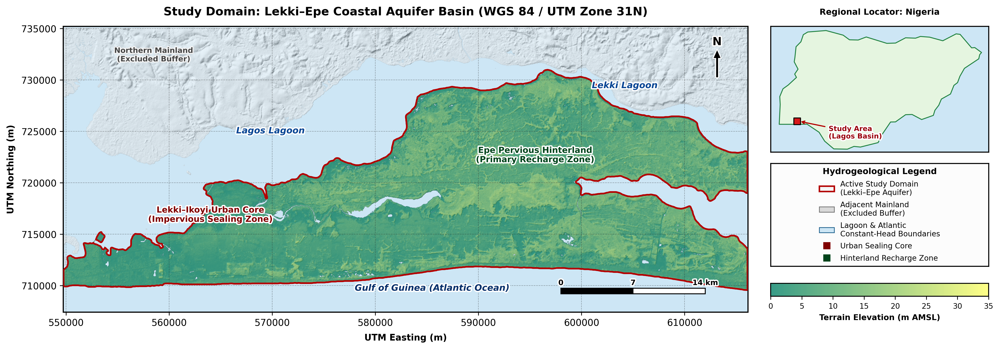

In [15]:
import time
import rasterio
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
from matplotlib.colors import LightSource
from scipy.ndimage import label, binary_fill_holes, binary_closing, gaussian_filter

tif_file = DATA_DIR / "lekki_multiband_utm31n.tif"

# Quick validation that the file exists before attempting to open
if not tif_file.exists():
    raise FileNotFoundError(f"Could not find the raster stack at {tif_file}. Please ensure the GEE export completed.")

# Robust file reading with retry logic to mitigate Google Drive I/O lag
max_retries = 3
for attempt in range(max_retries):
    try:
        with rasterio.open(tif_file) as src:
            meta = src.profile.copy()
            tfm = src.transform
            bnds = src.bounds
            ext = [bnds.left, bnds.right, bnds.bottom, bnds.top]
            res = abs(tfm.a)
            dem, slope, ndvi_24, ndbi_24, mndwi_24, ndvi_95, ndbi_95, rain = [src.read(i) for i in range(1, 9)]
        break
    except Exception as e:
        if attempt < max_retries - 1:
            print(f"Drive I/O lag encountered. Retrying in 5 seconds... ({attempt+1}/{max_retries})")
            time.sleep(5)
        else:
            raise e

valid = (dem > -50.0) & (~np.isnan(dem)) & (ndvi_24 > -2.0)
water = (mndwi_24 > 0.04) | (dem <= 0.5)
all_land = valid & (~water)

bridged = binary_closing(all_land, structure=np.ones((5, 5)))
struct_8 = np.ones((3, 3), dtype=int)
labeled_patches, _ = label(bridged, structure=struct_8)

mid_r, mid_c = int(dem.shape[0] * 0.62), int(dem.shape[1] * 0.52)
target_id = labeled_patches[mid_r, mid_c]

if target_id == 0:
    vals, counts = np.unique(labeled_patches[labeled_patches > 0], return_counts=True)
    target_id = vals[np.argmax(counts)]

focus_hull = binary_fill_holes(labeled_patches == target_id)
focus_aoi = focus_hull & all_land
other_land = all_land & (~focus_aoi)
land = focus_aoi.copy()

ls = LightSource(azdeg=315, altdeg=45)
dem_clean = np.where(valid, dem, 0.0)
hillshade = ls.hillshade(gaussian_filter(dem_clean, sigma=1.0), vert_exag=8.0, dx=res, dy=res)

fig = plt.figure(figsize=(15.5, 7.2), dpi=300, facecolor="white")

ax = fig.add_axes([0.06, 0.12, 0.66, 0.78])
ax.set_facecolor("#cde6f5")
ax.set_xlim(ext[0], ext[1])
ax.set_ylim(ext[2], ext[3])

ax.imshow(np.where(other_land, hillshade, np.nan), extent=ext, cmap="Greys_r", vmin=0, vmax=1, alpha=0.55)
ax.imshow(np.where(focus_aoi, hillshade, np.nan), extent=ext, cmap="gray", vmin=0, vmax=1, alpha=0.90)
im = ax.imshow(np.where(focus_aoi, dem, np.nan), extent=ext, cmap="summer", vmin=0, vmax=35, alpha=0.78)

X_grid = np.linspace(ext[0], ext[1], dem.shape[1])
Y_grid = np.linspace(ext[3], ext[2], dem.shape[0])
smooth_hull = gaussian_filter(focus_hull.astype(float), sigma=2.0)
ax.contour(X_grid, Y_grid, smooth_hull, levels=[0.5], colors=["#b30000"], linewidths=1.8, zorder=4)

ax.set_title("Study Domain: Lekki–Epe Coastal Aquifer Basin (WGS 84 / UTM Zone 31N)", fontsize=12.5, fontweight="bold", loc="center", pad=12)
ax.set_xlabel("UTM Easting (m)", fontsize=9.5, fontweight="bold", labelpad=6)
ax.set_ylabel("UTM Northing (m)", fontsize=9.5, fontweight="bold", labelpad=6)
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.4, color="#222222")

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_edgecolor("black")

halo_w = [pe.withStroke(linewidth=2.8, foreground="white")]
halo_soft = [pe.withStroke(linewidth=2.2, foreground="#f5f5f5")]

ax.text(566500, 724800, "Lagos Lagoon", fontsize=9.5, fontstyle="italic", fontweight="bold", color="#084594", path_effects=halo_w, zorder=6)
ax.text(601000, 729200, "Lekki Lagoon", fontsize=9.5, fontstyle="italic", fontweight="bold", color="#084594", path_effects=halo_w, zorder=6)
ax.text(578000, 709500, "Gulf of Guinea (Atlantic Ocean)", fontsize=9.5, fontstyle="italic", fontweight="bold", color="#08306b", path_effects=halo_w, zorder=6)
ax.text(558500, 731800, "Northern Mainland\n(Excluded Buffer)", fontsize=8, fontweight="bold", color="#444444", ha="center", path_effects=halo_soft, zorder=6)

ax.text(564000, 716200, "Lekki–Ikoyi Urban Core\n(Impervious Sealing Zone)", fontsize=9, fontweight="bold", color="#800000", ha="center", path_effects=halo_w, zorder=6)
ax.text(595500, 722000, "Epe Pervious Hinterland\n(Primary Recharge Zone)", fontsize=9, fontweight="bold", color="#00441b", ha="center", path_effects=halo_w, zorder=6)

ax.text(0.955, 0.945, "N", transform=ax.transAxes, ha="center", va="center", fontsize=12, fontweight="bold", color="black", path_effects=halo_w, zorder=7)
ax.annotate("", xy=(0.955, 0.92), xytext=(0.955, 0.82),
            xycoords="axes fraction", textcoords="axes fraction",
            arrowprops=dict(facecolor="black", edgecolor="white", linewidth=1.0, width=3.0, headwidth=9, headlength=10), zorder=7)

bx, by, bw = 598000, 709200, 14000.0
ax.add_patch(mpatches.Rectangle((bx, by), bw/2, 550, fc="black", ec="black", zorder=6))
ax.add_patch(mpatches.Rectangle((bx + bw/2, by), bw/2, 550, fc="white", ec="black", zorder=6))
ax.text(bx, by + 850, "0", ha="center", fontsize=8, fontweight="bold", path_effects=halo_w, zorder=6)
ax.text(bx + bw/2, by + 850, "7", ha="center", fontsize=8, fontweight="bold", path_effects=halo_w, zorder=6)
ax.text(bx + bw, by + 850, "14 km", ha="center", fontsize=8, fontweight="bold", path_effects=halo_w, zorder=6)

fig.canvas.draw()
pos = ax.get_position()
rx = pos.x1 + 0.022
rw = 0.21

h_in = pos.height * 0.44
ax_in = fig.add_axes([rx, pos.y1 - h_in, rw, h_in])
ax_in.set_facecolor("#cde6f5")
try:
    nga = gpd.read_file("https://raw.githubusercontent.com/johan/world.geo.json/master/countries/NGA.geo.json")
    nga.plot(ax=ax_in, color="#e5f5e0", edgecolor="#238443", linewidth=1.0)
except Exception:
    try:
        world = gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip")
        nga = world[world["NAME"] == "Nigeria"]
        nga.plot(ax=ax_in, color="#e5f5e0", edgecolor="#238443", linewidth=1.0)
    except Exception:
        pass

ax_in.set_aspect("auto")
ax_in.set_xlim(2.2, 15.0)
ax_in.set_ylim(4.0, 14.2)
ax_in.set_xlabel("")
ax_in.set_ylabel("")
ax_in.set_xticks([])
ax_in.set_yticks([])
for spine in ax_in.spines.values():
    spine.set_linewidth(1.1)
    spine.set_edgecolor("black")

ax_in.scatter([3.75], [6.50], color="#d7191c", s=50, marker="s", edgecolor="black", linewidth=1.0, zorder=5)
ax_in.annotate("Study Area\n(Lagos Basin)", xy=(3.85, 6.50), xytext=(5.6, 5.1),
               fontsize=7.5, fontweight="bold", color="#99000d", path_effects=halo_w,
               arrowprops=dict(arrowstyle="->", color="#b30000", lw=1.2))

# FIXED TITLE POSITIONING
ax_in.text(0.5, 1.08, "Regional Locator: Nigeria", transform=ax_in.transAxes,
           ha="center", va="bottom", fontsize=9, fontweight="bold", clip_on=False, zorder=6)

h_leg = pos.height * 0.36
y_leg = pos.y0 + (pos.height * 0.16)
ax_leg = fig.add_axes([rx, y_leg, rw, h_leg])
ax_leg.set_facecolor("#fcfcfc")
ax_leg.set_xticks([])
ax_leg.set_yticks([])
for spine in ax_leg.spines.values():
    spine.set_linewidth(1.1)
    spine.set_edgecolor("black")

legend_items = [
    mpatches.Patch(facecolor="#f5f5f5", edgecolor="#b30000", linewidth=1.6, label="Active Study Domain\n(Lekki–Epe Aquifer)"),
    mpatches.Patch(facecolor="#d9d9d9", edgecolor="#737373", linewidth=0.8, label="Adjacent Mainland\n(Excluded Buffer)"),
    mpatches.Patch(facecolor="#cde6f5", edgecolor="#1f618d", linewidth=0.8, label="Lagoon & Atlantic\nConstant-Head Boundaries"),
    mlines.Line2D([], [], color="#800000", marker="s", linestyle="None", markersize=6.5, label="Urban Sealing Core"),
    mlines.Line2D([], [], color="#00441b", marker="s", linestyle="None", markersize=6.5, label="Hinterland Recharge Zone")
]
leg = ax_leg.legend(handles=legend_items, loc="center", title="Hydrogeological Legend",
                    fontsize=8, title_fontsize=9, frameon=False, labelspacing=0.65)
leg.get_title().set_fontweight("bold")
leg.get_title().set_ha("center")

y_cb = pos.y0 + (pos.height * 0.055)
h_cb = pos.height * 0.045
cbar_ax = fig.add_axes([rx, y_cb, rw, h_cb])
cb = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cb.set_label("Terrain Elevation (m AMSL)", fontsize=8.5, fontweight="bold", labelpad=4)
cb.ax.tick_params(labelsize=8)
for spine in cbar_ax.spines.values():
    spine.set_linewidth(1.0)

plt.savefig(DATA_DIR / "fig0_study_area.png", bbox_inches="tight", facecolor="white")
plt.show()

In [16]:
dem_filled = np.where(valid, dem, np.median(dem[land]))
dem_blur = gaussian_filter(dem_filled, sigma=1.2)

gy, gx = np.gradient(dem_blur, res)
beta = np.arctan(np.sqrt(gx**2 + gy**2))
tan_b = np.tan(np.clip(beta, np.radians(0.1), np.radians(85.0)))

conv = gaussian_filter(-laplace(dem_blur), sigma=1.5)
catch_area = np.clip(conv - np.percentile(conv[land], 5) + 1.0, 1.0, None)
twi = np.log((catch_area * res) / tan_b)

def norm(arr, mask, ref=None):
    target = ref[mask] if ref is not None else arr[mask]
    low, high = np.percentile(target, [2, 98])
    scaled = np.clip((arr - low) / (high - low + 1e-8), 0.0, 1.0)
    return np.where(mask, scaled, 0.0)

# Stable slope weight calculation using clipped values to prevent exp() overflow
slope_clipped = np.clip(-slope / 5.0, -20.0, 20.0)
w_slope = norm(np.exp(slope_clipped), land)
w_twi = norm(twi, land)
w_rain = norm(rain, land)

w_perm_24 = 1.0 - norm(ndbi_24, land)
w_veg_24 = norm(ndvi_24, land)

valid_95 = (ndbi_95 > -1.0) & (ndbi_95 < 1.0) & (ndvi_95 > -1.0) & (ndvi_95 < 1.0) & land
rural_cols = np.zeros_like(land, dtype=bool)
rural_cols[:, int(land.shape[1] * 0.70):] = True
ref_zone = valid_95 & rural_cols

ndbi_shift = np.median(ndbi_24[ref_zone]) - np.median(ndbi_95[ref_zone])
ndvi_shift = np.median(ndvi_24[ref_zone]) - np.median(ndvi_95[ref_zone])

ndbi_95_cal = np.where(valid_95, ndbi_95 + ndbi_shift, np.median(ndbi_95[valid_95]) + ndbi_shift)
ndvi_95_cal = np.where(valid_95, ndvi_95 + ndvi_shift, np.median(ndvi_95[valid_95]) + ndvi_shift)

w_perm_95 = 1.0 - norm(ndbi_95_cal, land, ref=ndbi_24)
w_veg_95 = norm(ndvi_95_cal, land, ref=ndvi_24)

arpi_24 = (0.30 * w_perm_24) + (0.25 * w_slope) + (0.20 * w_twi) + (0.15 * w_rain) + (0.10 * w_veg_24)
arpi_95 = (0.30 * w_perm_95) + (0.25 * w_slope) + (0.20 * w_twi) + (0.15 * w_rain) + (0.10 * w_veg_95)

k_max = 0.35
rch_24 = np.where(land, rain * k_max * arpi_24, -9999.0).astype(np.float32)
rch_95 = np.where(land, rain * k_max * arpi_95, -9999.0).astype(np.float32)

out_meta = meta.copy()
out_meta.update({"count": 1, "dtype": "float32", "nodata": -9999.0, "compress": "lzw"})

outputs = {
    "arpi_2024.tif": np.where(land, arpi_24, -9999.0),
    "arpi_1995.tif": np.where(land, arpi_95, -9999.0),
    "modflow_rch_2024_mmyr.tif": rch_24
}

for fname, data in outputs.items():
    with rasterio.open(DATA_DIR / fname, "w", **out_meta) as dst:
        dst.write(data.astype(np.float32), 1)

mean_95 = float(arpi_95[land].mean())
mean_24 = float(arpi_24[land].mean())
drop_pct = ((mean_95 - mean_24) / mean_95) * 100.0
rch_mean_95 = float((rain[land] * k_max * arpi_95[land]).mean())
rch_mean_24 = float((rain[land] * k_max * arpi_24[land]).mean())

west_urban = land.copy()
west_urban[:, int(land.shape[1] * 0.45):] = False
u_mean_95 = float(arpi_95[west_urban].mean())
u_mean_24 = float(arpi_24[west_urban].mean())
u_drop_pct = ((u_mean_95 - u_mean_24) / u_mean_95) * 100.0

print(f"Whole Basin -> 1995 Mean: {mean_95:.4f} | 2024 Mean: {mean_24:.4f} | Change: -{drop_pct:.2f}%")
print(f"Lekki Urban Core -> 1995 Mean: {u_mean_95:.4f} | 2024 Mean: {u_mean_24:.4f} | Change: -{u_drop_pct:.2f}%")
print(f"Effective Recharge -> {rch_mean_95:.1f} mm/yr (1995) to {rch_mean_24:.1f} mm/yr (2024)")

Whole Basin -> 1995 Mean: 0.4274 | 2024 Mean: 0.4054 | Change: -5.16%
Lekki Urban Core -> 1995 Mean: 0.3755 | 2024 Mean: 0.3074 | Change: -18.14%
Effective Recharge -> 266.9 mm/yr (1995) to 253.3 mm/yr (2024)


In [17]:
# Check if the required preceding variables exist in memory before running
if 'arpi_24' not in globals() or 'land' not in globals():
    raise NameError(
        "Required variables 'arpi_24' and 'land' are missing from memory.\n"
        "Please ensure you run cell G0dYcH2Es2a6 (data loading) and cell 7L2zWtu3y5_u (ARPI calculations) first."
    )

import numpy as np
import pandas as pd
import json
import rasterio
from skimage.graph import route_through_array

friction = np.full(arpi_24.shape, 1e6, dtype=np.float64)
friction[land] = np.exp(4.0 * (1.0 - arpi_24[land]))

def snap_land(mask, r_idx, c_idx):
    vr, vc = np.where(mask)
    d2 = (vr - r_idx)**2 + (vc - c_idx)**2
    best = np.argmin(d2)
    return (int(vr[best]), int(vc[best]))

nrows, ncols = arpi_24.shape
src_pt = snap_land(land, int(nrows * 0.25), int(ncols * 0.82))
dst_pt = snap_land(land, int(nrows * 0.72), int(ncols * 0.18))

route, cost = route_through_array(friction, src_pt, dst_pt, fully_connected=True, geometric=True)

rr, cc = zip(*route)
prof_24 = arpi_24[rr, cc]
prof_95 = arpi_95[rr, cc]

choke_mask = prof_24 < 0.35
choke_xy = [rasterio.transform.xy(tfm, r, c) for r, c, m in zip(rr, cc, choke_mask) if m]
route_xy = [list(rasterio.transform.xy(tfm, r, c)) for r, c in route]

with open(DATA_DIR / "percolation_corridor.geojson", "w") as f:
    json.dump({
        "type": "FeatureCollection",
        "crs": {"type": "name", "properties": {"name": "urn:ogc:def:crs:EPSG::32631"}},
        "features": [{
            "type": "Feature",
            "properties": {
                "length_km": round(len(route) * res / 1000.0, 2),
                "cost": round(float(cost), 2),
                "choke_nodes": int(np.sum(choke_mask))
            },
            "geometry": {"type": "LineString", "coordinates": route_xy}
        }]
    }, f, indent=2)

stats = pd.DataFrame({
    "Metric": [
        "Modeled Unconfined Land Area (km2)",
        "1995 Whole-Basin Mean ARPI",
        "2024 Whole-Basin Mean ARPI",
        "Whole-Basin Recharge Attenuation (%)",
        "1995 Lekki Urban Sector Mean ARPI",
        "2024 Lekki Urban Sector Mean ARPI",
        "Lekki Urban Recharge Attenuation (%)",
        "1995 Mean Effective Recharge (mm/yr)",
        "2024 Mean Effective Recharge (mm/yr)",
        "Basin Area Below Choke Threshold (ARPI < 0.35) [%]",
        "Routed Corridor Length (km)",
        "Corridor Choke Points (Pixels < 0.35)"
    ],
    "Value": [
        round(np.sum(land) * (res**2) / 1e6, 2),
        round(mean_95, 4),
        round(mean_24, 4),
        round(drop_pct, 2),
        round(u_mean_95, 4),
        round(u_mean_24, 4),
        round(u_drop_pct, 2),
        round(rch_mean_95, 1),
        round(rch_mean_24, 1),
        round(float(np.mean(arpi_24[land] < 0.35) * 100), 2),
        round(len(route) * res / 1000.0, 2),
        int(np.sum(choke_mask))
    ]
})

stats.to_csv(DATA_DIR / "summary_metrics.csv", index=False)
display(stats)

,Metric,Value
0,Modeled Unconfined Land Area (km2),766.1000
1,1995 Whole-Basin Mean ARPI,0.4274
2,2024 Whole-Basin Mean ARPI,0.4054
3,Whole-Basin Recharge Attenuation (%),5.1600
4,1995 Lekki Urban Sector Mean ARPI,0.3755
5,2024 Lekki Urban Sector Mean ARPI,0.3074
6,Lekki Urban Recharge Attenuation (%),18.1400
7,1995 Mean Effective Recharge (mm/yr),266.9000
8,2024 Mean Effective Recharge (mm/yr),253.3000
9,Basin Area Below Choke Threshold (ARPI < 0.35)...,33.2400


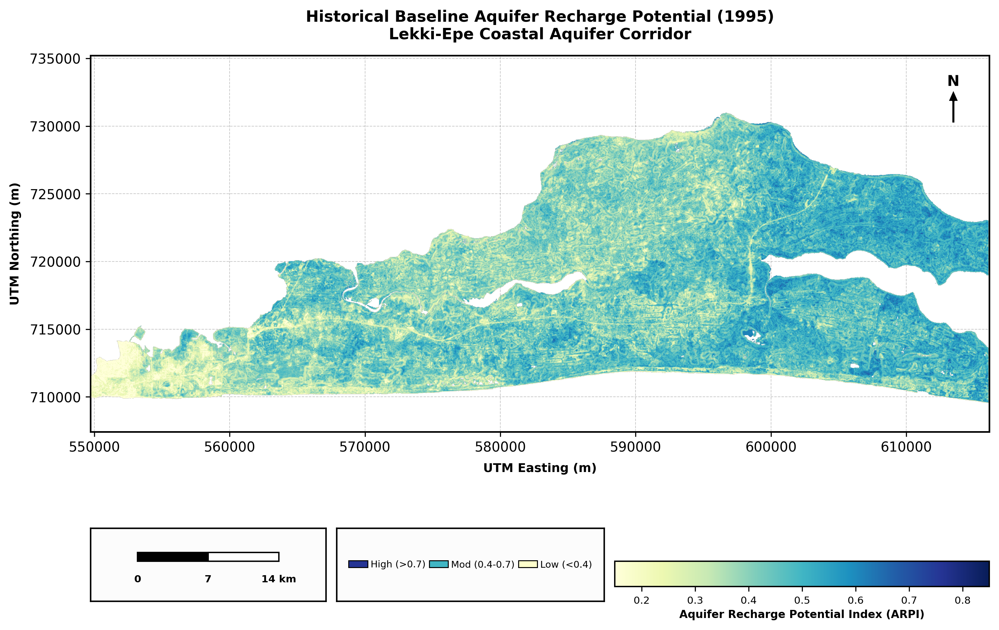

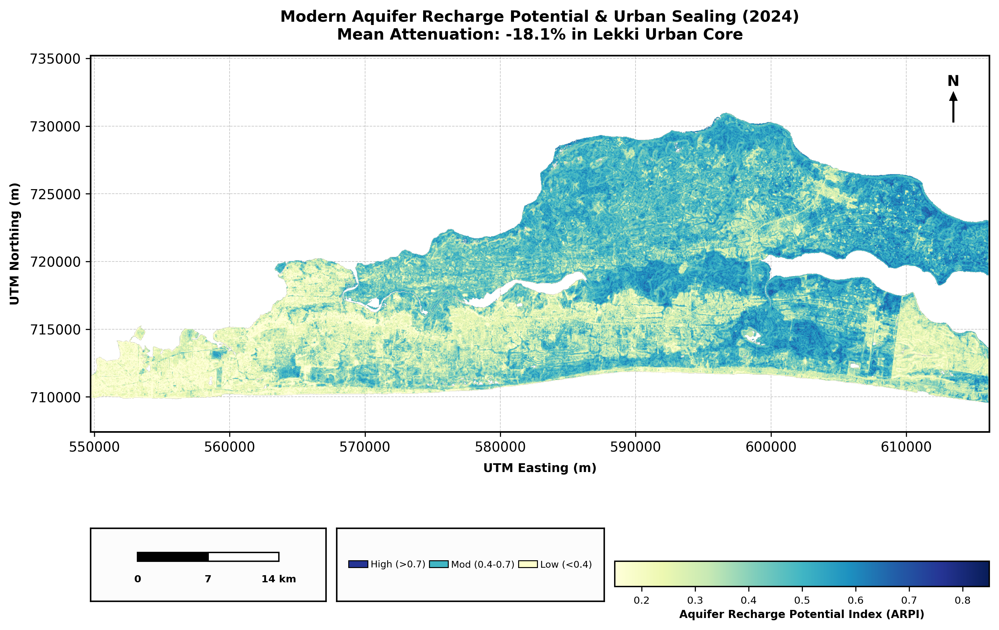

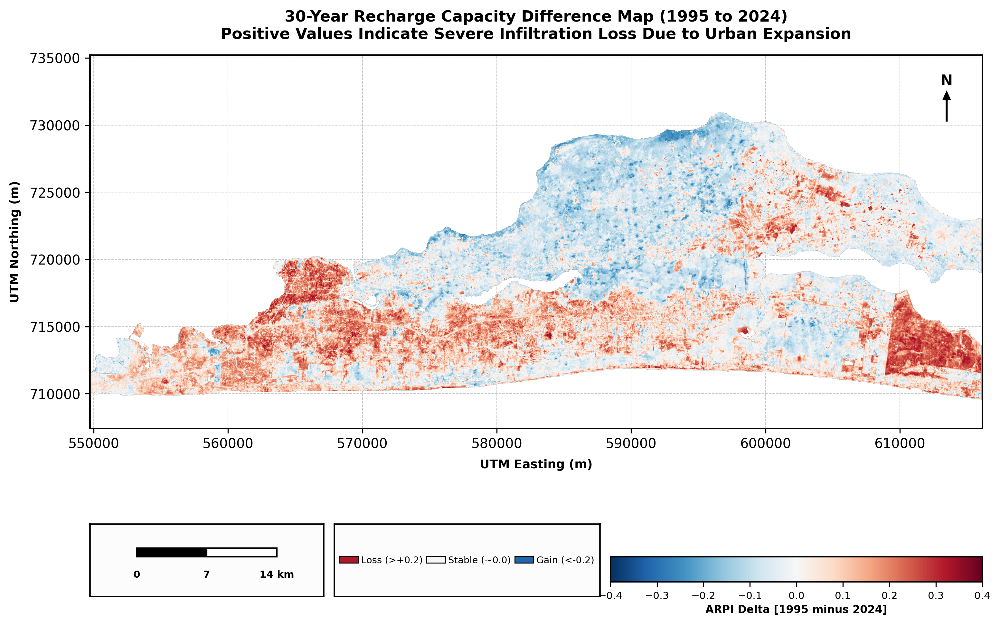

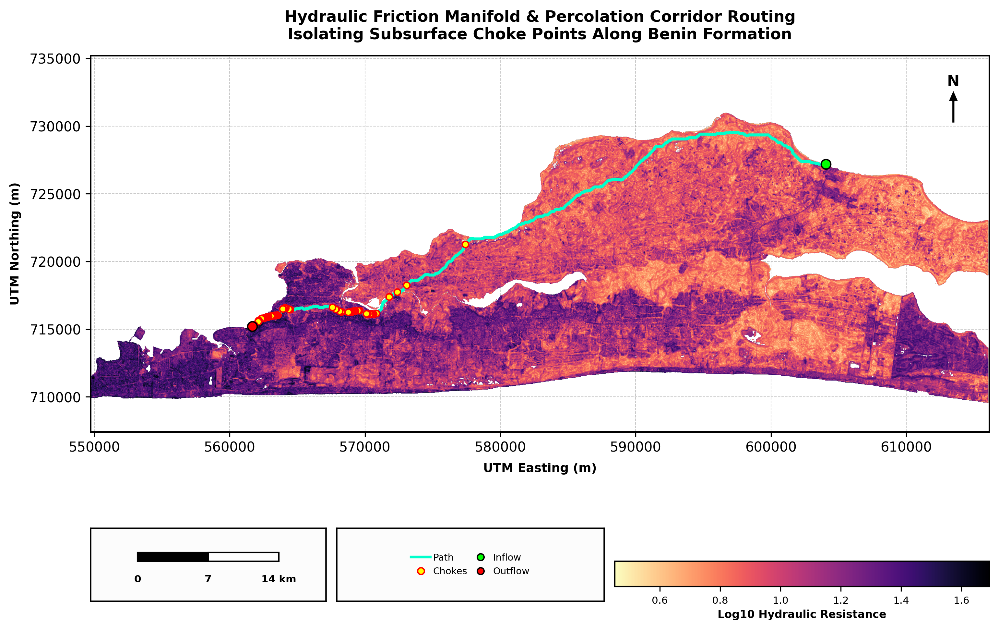

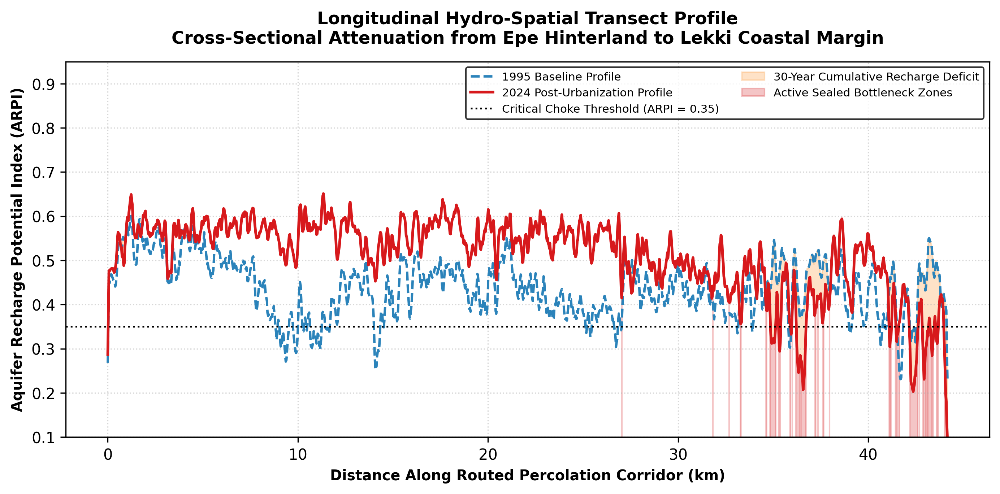

In [26]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
import numpy as np

halo_w = [pe.withStroke(linewidth=2.5, foreground="white")]

def create_cartographic_map(data_arr, cmap_name, vmin_val, vmax_val, title_text, cbar_label, leg_handles, is_routing=False):
    fig = plt.figure(figsize=(11, 7.5), dpi=300, facecolor="white")

    # Main map axis
    ax = fig.add_axes([0.08, 0.20, 0.84, 0.70])
    ax.set_facecolor("#ffffff")
    ax.set_xlim(ext[0], ext[1])
    ax.set_ylim(ext[2], ext[3])

    im = ax.imshow(np.where(land, data_arr, np.nan), extent=ext, cmap=cmap_name, vmin=vmin_val, vmax=vmax_val, zorder=3)
    ax.set_title(title_text, fontsize=11.5, fontweight="bold", pad=12)
    ax.set_xlabel("UTM Easting (m)", fontsize=9, fontweight="bold", labelpad=6)
    ax.set_ylabel("UTM Northing (m)", fontsize=9, fontweight="bold", labelpad=6)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.35, color="#666666", zorder=2)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_edgecolor("black")

    # North arrow in top-right corner
    ax.text(0.96, 0.93, "N", transform=ax.transAxes, ha="center", va="center", fontsize=11, fontweight="bold", color="black", path_effects=halo_w, zorder=7)
    ax.annotate("", xy=(0.96, 0.91), xytext=(0.96, 0.82),
                xycoords="axes fraction", textcoords="axes fraction",
                arrowprops=dict(facecolor="black", edgecolor="white", linewidth=1.0, width=2.5, headwidth=8, headlength=9), zorder=7)

    # --- DEDICATED SCALE BAR PANEL (Bottom Left - Completely Outside Map) ---
    ax_scale = fig.add_axes([0.08, 0.06, 0.22, 0.10])
    ax_scale.set_facecolor("#fcfcfc")
    ax_scale.set_xticks([])
    ax_scale.set_yticks([])
    for spine in ax_scale.spines.values():
        spine.set_linewidth(1.1)
        spine.set_edgecolor("black")

    # Draw scale bar inside its own container box
    bx, by, bw = 0.5, 0.5, 0.6
    ax_scale.add_patch(mpatches.Rectangle((0.2, 0.55), bw, 0.12, fc="black", ec="black", transform=ax_scale.transAxes, zorder=2))
    ax_scale.add_patch(mpatches.Rectangle((0.5, 0.55), bw/2, 0.12, fc="white", ec="black", transform=ax_scale.transAxes, zorder=3))
    ax_scale.text(0.2, 0.3, "0", ha="center", va="center", transform=ax_scale.transAxes, fontsize=7.5, fontweight="bold")
    ax_scale.text(0.5, 0.3, "7", ha="center", va="center", transform=ax_scale.transAxes, fontsize=7.5, fontweight="bold")
    ax_scale.text(0.8, 0.3, "14 km", ha="center", va="center", transform=ax_scale.transAxes, fontsize=7.5, fontweight="bold")

    # --- COMPACT LEGEND PANEL (Middle-Bottom) ---
    ax_leg = fig.add_axes([0.31, 0.06, 0.25, 0.10])
    ax_leg.set_facecolor("#fcfcfc")
    ax_leg.set_xticks([])
    ax_leg.set_yticks([])
    for spine in ax_leg.spines.values():
        spine.set_linewidth(1.1)
        spine.set_edgecolor("black")
    col_cnt = 2 if is_routing else 3
    ax_leg.legend(handles=leg_handles, loc="center", ncol=col_cnt, fontsize=7, frameon=False, columnspacing=0.4, handletextpad=0.3)

    # --- COLORBAR PANEL (Bottom Right) ---
    cbar_ax = fig.add_axes([0.57, 0.08, 0.35, 0.035])
    cb = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
    cb.set_label(cbar_label, fontsize=8, fontweight="bold", labelpad=3)
    cb.ax.tick_params(labelsize=7.5)
    for spine in cbar_ax.spines.values():
        spine.set_linewidth(1.0)

    return fig

# ==========================================
# 1. HISTORICAL BASELINE ARPI (1995)
# ==========================================
leg_items_base = [
    mpatches.Patch(facecolor="#253494", edgecolor="black", linewidth=0.7, label="High (>0.7)"),
    mpatches.Patch(facecolor="#41b6c4", edgecolor="black", linewidth=0.7, label="Mod (0.4-0.7)"),
    mpatches.Patch(facecolor="#ffffcc", edgecolor="black", linewidth=0.7, label="Low (<0.4)")
]
fig1 = create_cartographic_map(
    arpi_95, "YlGnBu", 0.15, 0.85,
    "Historical Baseline Aquifer Recharge Potential (1995)\nLekki-Epe Coastal Aquifer Corridor",
    "Aquifer Recharge Potential Index (ARPI)", leg_items_base
)
plt.savefig(DATA_DIR / "1995_Baseline_ARPI.png", bbox_inches="tight", facecolor="white")
plt.show()

# ==========================================
# 2. MODERN ARPI & URBAN SEALING (2024)
# ==========================================
fig2 = create_cartographic_map(
    arpi_24, "YlGnBu", 0.15, 0.85,
    f"Modern Aquifer Recharge Potential & Urban Sealing (2024)\nMean Attenuation: -{u_drop_pct:.1f}% in Lekki Urban Core",
    "Aquifer Recharge Potential Index (ARPI)", leg_items_base
)
plt.savefig(DATA_DIR / "2024_Modern_ARPI.png", bbox_inches="tight", facecolor="white")
plt.show()

# ==========================================
# 3. TEMPORAL DELTA MAP (1995 vs 2024)
# ==========================================
arpi_loss = np.where(land, arpi_95 - arpi_24, np.nan)
leg_items_delta = [
    mpatches.Patch(facecolor="#b2182b", edgecolor="black", linewidth=0.7, label="Loss (>+0.2)"),
    mpatches.Patch(facecolor="#f7f7f7", edgecolor="black", linewidth=0.7, label="Stable (~0.0)"),
    mpatches.Patch(facecolor="#2166ac", edgecolor="black", linewidth=0.7, label="Gain (<-0.2)")
]
fig3 = create_cartographic_map(
    arpi_loss, "RdBu_r", -0.4, 0.4,
    "30-Year Recharge Capacity Difference Map (1995 to 2024)\nPositive Values Indicate Severe Infiltration Loss Due to Urban Expansion",
    "ARPI Delta [1995 minus 2024]", leg_items_delta
)
plt.savefig(DATA_DIR / "ARPI_Temporal_Delta_Map.png", bbox_inches="tight", facecolor="white")
plt.show()

# ==========================================
# 4. HYDRAULIC FRICTION & PERCOLATION ROUTING
# ==========================================
leg_items_routing = [
    mlines.Line2D([], [], color="#00ffcc", lw=2.0, label="Path"),
    mlines.Line2D([], [], color="yellow", marker="o", markeredgecolor="red", linestyle="None", markersize=5, label="Chokes"),
    mlines.Line2D([], [], color="lime", marker="o", markeredgecolor="black", linestyle="None", markersize=5, label="Inflow"),
    mlines.Line2D([], [], color="red", marker="o", markeredgecolor="black", linestyle="None", markersize=5, label="Outflow")
]
fig4 = create_cartographic_map(
    np.log10(friction), "magma_r", np.log10(friction[land]).min(), np.log10(friction[land]).max(),
    "Hydraulic Friction Manifold & Percolation Corridor Routing\nIsolating Subsurface Choke Points Along Benin Formation",
    "Log10 Hydraulic Resistance", leg_items_routing, is_routing=True
)
ax_rt = fig4.axes[0]
r_xy = np.array(route_xy)
ax_rt.plot(r_xy[:, 0], r_xy[:, 1], color="#00ffcc", lw=2.2, zorder=4)
if len(choke_xy) > 0:
    c_xy = np.array(choke_xy)
    ax_rt.scatter(c_xy[:, 0], c_xy[:, 1], color="yellow", edgecolor="red", s=22, zorder=5)
ax_rt.scatter(r_xy[0, 0], r_xy[0, 1], color="lime", edgecolor="black", s=50, zorder=6)
ax_rt.scatter(r_xy[-1, 0], r_xy[-1, 1], color="red", edgecolor="black", s=50, zorder=6)

plt.savefig(DATA_DIR / "Percolation_Routing_Map.png", bbox_inches="tight", facecolor="white")
plt.show()

# ==========================================
# 5. LONGITUDINAL TRANSECT PROFILE
# ==========================================
fig5, ax5 = plt.subplots(figsize=(11, 4.5), dpi=300, facecolor="white")
dist = np.arange(len(prof_24)) * (res / 1000.0)
k = np.ones(5) / 5.0
s95 = np.convolve(prof_95, k, mode='same')
s24 = np.convolve(prof_24, k, mode='same')

ax5.plot(dist, s95, color="#2b83ba", lw=1.6, linestyle="--", label="1995 Baseline Profile")
ax5.plot(dist, s24, color="#d7191c", lw=1.8, label="2024 Post-Urbanization Profile")
ax5.axhline(0.35, color="black", linestyle=":", lw=1.2, label="Critical Choke Threshold (ARPI = 0.35)")
ax5.fill_between(dist, s24, s95, where=(s95 > s24), color="#fdae61", alpha=0.35, label="30-Year Cumulative Recharge Deficit")
ax5.fill_between(dist, 0, s24, where=(prof_24 < 0.35), color="#d7191c", alpha=0.25, label="Active Sealed Bottleneck Zones")

ax5.set_title("Longitudinal Hydro-Spatial Transect Profile\nCross-Sectional Attenuation from Epe Hinterland to Lekki Coastal Margin", fontsize=11.5, fontweight="bold", pad=12)
ax5.set_xlabel("Distance Along Routed Percolation Corridor (km)", fontsize=9.5, fontweight="bold")
ax5.set_ylabel("Aquifer Recharge Potential Index (ARPI)", fontsize=9.5, fontweight="bold")
ax5.set_ylim(0.1, 0.95)
ax5.grid(True, linestyle=":", alpha=0.5)
ax5.legend(loc="upper right", fontsize=7.5, ncol=2, frameon=True, facecolor="white", edgecolor="black")

plt.savefig(DATA_DIR / "Longitudinal_Transect_Profile.png", bbox_inches="tight", facecolor="white")
plt.show()


In [31]:
!pip install flopy -q

import flopy
import rasterio
import numpy as np
from pathlib import Path

rch_tif = DATA_DIR / "modflow_rch_2024_mmyr.tif"
with rasterio.open(rch_tif) as src:
    rch_array = src.read(1)
    nodata_val = src.nodata
    nrow, ncol = rch_array.shape
    delr = delc = abs(src.transform.a)

# Replace nodata with zero or a baseline minimum recharge for inactive cells
rch_clean = np.where(rch_array == nodata_val, 0.0, rch_array)

# Initialize MODFLOW 6 Workspace Simulation
sim_name = "lekki_gw_model"
sim = flopy.mf6.MFSimulation(sim_name=sim_name, exe_name="mf6", version="mf6", sim_ws=str(DATA_DIR / "mf6_model"))

# Create Temporal Discretization (Steady-state / Annual Stress Period)
tdis = flopy.mf6.ModflowTdis(sim, time_units="DAYS", nper=1, perioddata=[(365.0, 1, 1.0)])

# Create Iterative Model Solution (IMS) - Fixed bratings to print_option
ims = flopy.mf6.ModflowIms(sim, print_option="SUMMARY", complexity="MODERATE")

# Create Groundwater Flow Model Instance
gwf = flopy.mf6.ModflowGwf(sim, modelname=sim_name, save_flows=True)

# Define Discretization (Grid Layout matching your 30m GeoTIFF)
dis = flopy.mf6.ModflowGwfdis(
    gwf,
    nlay=1,
    nrow=nrow,
    ncol=ncol,
    delr=delr,
    delc=delc,
    top=45.0,
    botm=0.0
)

# Initial Heads & Node Property Flow
ic = flopy.mf6.ModflowGwfic(gwf, strt=5.0)
npf = flopy.mf6.ModflowGwfnpf(gwf, save_flows=True, icelltype=1)

# --- INGEST ARPI RECHARGE ARRAY DIRECTLY INTO MODFLOW 6 RCHA PACKAGE ---
# Using the array-based recharge package (rcha) to accept our spatial 2D array
rch = flopy.mf6.ModflowGwfrcha(
    gwf,
    recharge=rch_clean
)

# Output Control
oc = flopy.mf6.ModflowGwfoc(
    gwf,
    budget_filerecord=f"{sim_name}.bud",
    head_filerecord=f"{sim_name}.hds",
    saverecord=[("HEAD", "ALL"), ("BUDGET", "ALL")]
)

sim.write_simulation()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model lekki_gw_model...
    writing model name file...
    writing package dis...
    writing package ic...
    writing package npf...
    writing package rcha_0...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

    writing package oc...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [32]:
import os
from pathlib import Path

model_dir = DATA_DIR / "mf6_model"
if model_dir.exists():
    files = sorted(list(model_dir.glob("*")))
    print(f"Contents of {model_dir}: {len(files)} files found.\n")
    for f in files:
        print(f" - {f.name} ({f.stat().st_size / 1024:.2f} KB)")
else:
    print(f"Directory does not exist: {model_dir}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Contents of /content/drive/MyDrive/Lekki_Hydro_Study/mf6_model: 9 files found.

 - lekki_gw_model.dis (0.33 KB)
 - lekki_gw_model.ic (0.16 KB)
 - lekki_gw_model.ims (0.14 KB)
 - lekki_gw_model.nam (0.29 KB)
 - lekki_gw_model.npf (0.19 KB)
 - lekki_gw_model.oc (0.23 KB)
 - lekki_gw_model.rcha (34038.81 KB)
 - lekki_gw_model.tdis (0.22 KB)
 - mfsim.nam (0.33 KB)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag